# **Module 05: Random Variables and Probability Distributions**

---

## 📌 Overview

A **Random Variable** is the mathematical bridge that maps the outcomes of a random experiment to numerical values, allowing us to model uncertain phenomena in a structured way. **Probability Distributions**, in turn, describe how probability behaves across all possible values of that variable.

Understanding these theoretical models is a crucial step in Data Science: they form the foundation for hypothesis testing, confidence intervals, simulations, and many Machine Learning algorithms. In this notebook, we will explore the main discrete and continuous distributions and how to apply them in practice using Python.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Differentiate between discrete and continuous random variables**, identifying which model applies to each real-world problem.
* **Interpret and compute probability functions**: Probability Mass Function (PMF), Probability Density Function (PDF), and Cumulative Distribution Function (CDF).
* **Calculate and interpret theoretical measures** of a distribution, such as **Expected Value** ($E[X]$) and **Variance** ($\text{Var}(X)$).
* **Apply the main discrete distributions** (Bernoulli, Binomial, and Poisson) to model successes, failures, and event counts.
* **Apply the main continuous distributions** (Uniform, Normal, and Exponential) to model durations, physical measurements, and natural phenomena.
* **Perform standardization ($Z$-score)** and calculate cumulative probabilities and quantiles using `scipy.stats`.

---

## 🧭 Module Structure

1. **Random Variables** — Definition and distinction between discrete and continuous variables.
2. **Probability Functions and Moments** — PMF, PDF, CDF, Expected Value, and Variance.
3. **Main Discrete Distributions** — Bernoulli, Binomial, and Poisson.
4. **Main Continuous Distributions** — Uniform, Exponential, and Normal (Gaussian).
5. **Standard Normal Distribution and $Z$-Score** — Data standardization and the Empirical Rule (68–95–99.7).
6. **Hands-on Python** — Probability calculations, synthetic sample generation, and visualizations using `scipy.stats`, `numpy`, `matplotlib`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Introduction to Probability** (*Module 04*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `matplotlib`, and `seaborn`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import chi2_contingency, spearmanr

## **Random Variables**
A random variable associates a single numerical value with each outcome of a random experiment. It can be:

* `Discrete random variable:` takes a finite or countable set of values, generally resulting from counts. *Examples: number of children, number of employees in a company, number of computers in a room...*

* `Continuous random variable:` takes any value within an interval of real numbers. *Examples: family income, company revenue, weight, height...*

### **Discrete Random Variables (DRV)**

Let $X$ be a DRV that can take the values $\{x_1, x_2, ..., x_n\}$ with probabilities $\{p(x_1), p(x_2), ..., p(x_n)\}$. The probability mass function (PMF) is:

$P(X = x_i) = p(x_i) = p_i, \forall\ i=1,...,n$

where
$p(x_i)\geq 0\ \forall\ x_i\ \text{and}\ \sum p(x_i) = 1$

#### **Expected Value of a DRV**
The expected, or mean, value of $X$.

$E(X) = \sum_{i=1}^{n} x_i\cdot P(X = x_i)$

#### **Variance and Standard Deviation of a DRV**

$Var(X) = \sum_{i=1}^n(x_i - E(X))^2\cdot p_i$

$\sigma(X) = \sqrt{Var(X)}$

In [2]:
# Example: number of sales per day and their probabilities
sales = [0., 1., 2., 3.]
px = [2/10, 4/10, 3/10, 1/10]

In [3]:
expected_val = []
for i, j in zip(sales, px):
    expected_val.append(i * j)

expected_val = sum(expected_val)
expected_val

1.3

In [4]:
var = []
for i, j in zip(sales, px):
    var_ = ((i - expected_val)**2) * j
    var.append(var_)

var = sum(var)
print(f"Variance: {np.round(var, 2)}")
print(f"Standard deviation: {np.round(np.sqrt(var), 2)}")

Variance: 0.81
Standard deviation: 0.9


#### **Cumulative Distribution Function (CDF) of a DRV**
The sum of the probabilities of all values $x_i \leq x$.

$F(x) = P(X \leq x) = \sum_{x_i \leq x} p(x_i)$

`Properties`<p>
$0 \leq F(x) \leq 1$<p>
$\lim_{x\rightarrow +\infty}F(x) = 1$<p>
$\lim_{x\rightarrow -\infty}F(x) = 0$<p>
$a < b \rightarrow F(a) \leq F(b)$

In [5]:
cumulative = []
for i in range(len(px)):
    if i <= 0:
        cumulative.append(px[i])
    else:
        cumulative.append(np.round(cumulative[i-1] + px[i], 2))
cumulative

[0.2, np.float64(0.6), np.float64(0.9), np.float64(1.0)]

In [6]:
def cdf_func(value):
    for i in range(len(px)):
        if value >= sales[i]:
            p_value = cumulative[i]
        elif value < 0:
            p_value = 0

    return p_value

assert cdf_func(0.5) == 2/10
assert cdf_func(1) == 6/10
assert cdf_func(2.5) == 9/10
assert cdf_func(3) == 1
assert cdf_func(4) == 1
assert cdf_func(-0.5) == 0

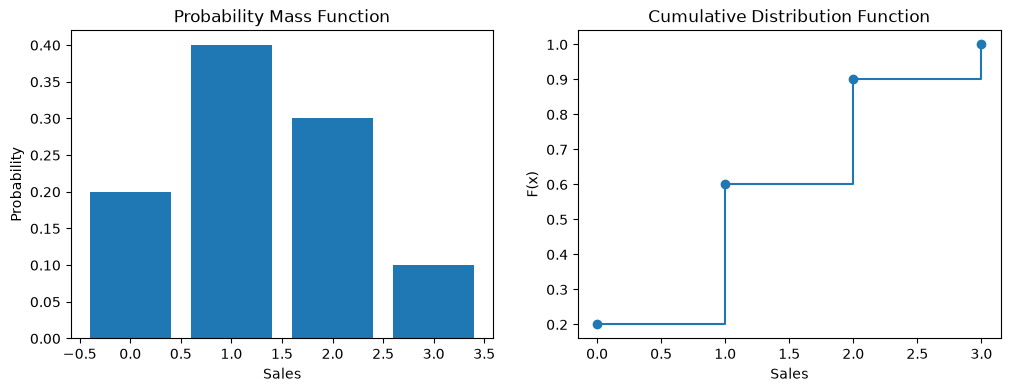

In [7]:
# PMF and CDF of daily sales
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(sales, px)
ax[0].set_title('Probability Mass Function')
ax[0].set_xlabel('Sales')
ax[0].set_ylabel('Probability')

ax[1].step(sales, cumulative, where='post', marker='o')
ax[1].set_title('Cumulative Distribution Function')
ax[1].set_xlabel('Sales')
ax[1].set_ylabel('F(x)')

# Display the chart
plt.show()

### **Continuous Random Variables (CRV)**
Let $X$ be a continuous variable associated with a probability density function (PDF) $f(x)$:<p>
$f(x)\geq 0$ and $\int_{-\infty}^{+\infty}f(x)dx = 1$<p>

For any $a$ and $b$ such that $-\infty < a < b < +\infty$:<p>
$P(a\leq X\leq b) = \int_{a}^{b}f(x)dx$

#### **Expected Value of a CRV**

$E(X)= \int_{-\infty}^{+\infty}x\cdot f(x)dx$

#### **Variance and Standard Deviation of a CRV**

$Var(X) = \int_{-\infty}^{+\infty}(x - E(X))^2\cdot f(x)dx$

$\sigma(X) = \sqrt{Var(X)}$

#### **Cumulative Distribution Function (CDF) of a CRV**

$F(x) = P(X \leq x) = \int_{-\infty}^{x}f(t)dt, \quad -\infty < x < +\infty$ <p>
`Properties`<p>
$0 \leq F(x) \leq 1$<p>
$\lim_{x\rightarrow +\infty}F(x) = 1$<p>
$\lim_{x\rightarrow -\infty}F(x) = 0$<p>
$a < b \rightarrow F(a) \leq F(b)$

### **Probability Distributions for Discrete Random Variables**

#### **Discrete Uniform Distribution**
All $n$ possible values have the same probability.

$P(X = x_i) = p(x_i) = \frac{1}{n}, \quad i = 1, 2, ..., n$

*Example: rolling a fair die.*

In [8]:
X = [1., 2., 3., 4., 5., 6.]
fx = [1/6, 1/6, 1/6, 1/6, 1/6, 1/6]

##### **Expected Value**

$E(X) = \frac{1}{n}\sum_{i=1}^n x_i$

In [9]:
ex = sum(X) * (1 / len(X))
ex

3.5

##### **Variance**

$Var(X)=\frac{1}{n}\left[\sum_{i=1}^n x_i^2 - \frac{(\sum_{i=1}^n x_i)^2}{n}\right]$

In [10]:
x2 = []
for i in X:
    x2.append(i**2)
x2

[1.0, 4.0, 9.0, 16.0, 25.0, 36.0]

In [11]:
var = (1 / len(X)) * (sum(x2) - ((sum(X)**2) / len(X)))
var

2.9166666666666665

##### **Cumulative Distribution Function (CDF)**

$F(x)=P(X\leq x)=\sum_{x_i\leq x}\frac{1}{n}=\frac{n(x)}{n}$

where $n(x)$ is the number of values $x_i \leq x$.

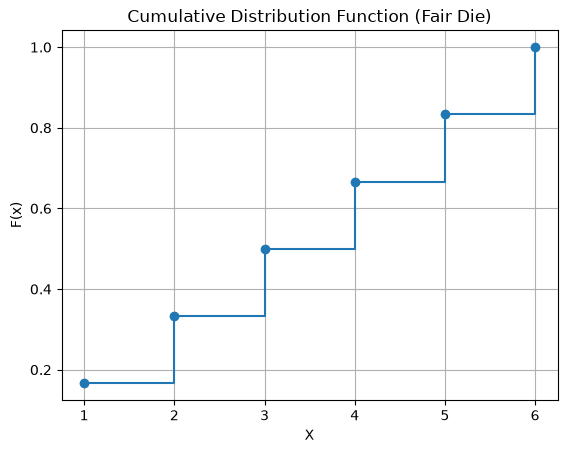

In [12]:
# Calculate cumulative probability
cumulative_prob = np.cumsum(fx)

# Create cumulative distribution chart
plt.step(X, cumulative_prob, where='post', marker='o')
plt.xlabel('X')
plt.ylabel('F(x)')
plt.title('Cumulative Distribution Function (Fair Die)')
plt.grid(True)

# Display the chart
plt.show()

#### **Bernoulli Distribution**
An experiment with only two outcomes: success ($X = 1$), with probability $p$, and failure ($X = 0$), with probability $1 - p$.

$P(X = x) = p^x(1-p)^{1-x}, \quad x \in \{0, 1\}$

$E(X) = p \quad Var(X) = p(1-p)$

*Example: whether a manufactured part is defective or not.*

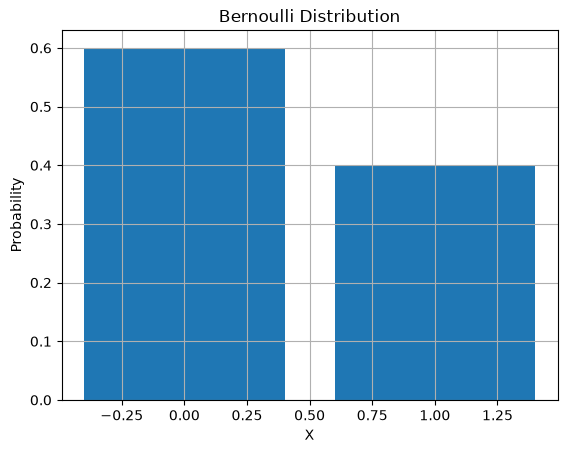

In [13]:
from scipy.stats import bernoulli

# Probability of success (event occurrence)
p = 0.4

# Values of X (failure or success)
x_values = [0, 1]

# Calculate probability for each value of X
probability = bernoulli.pmf(x_values, p)

# Create Bernoulli distribution chart
plt.bar(x_values, probability)
plt.xlabel('X')
plt.ylabel('Probability')
plt.title('Bernoulli Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Binomial Distribution**
Number of successes $k$ in $n$ independent Bernoulli trials, each with probability of success $p$.

$P(X = k) = \binom{n}{k}p^k(1-p)^{n-k}, \quad k = 0, 1, ..., n$

$E(X) = np \quad Var(X) = np(1-p)$

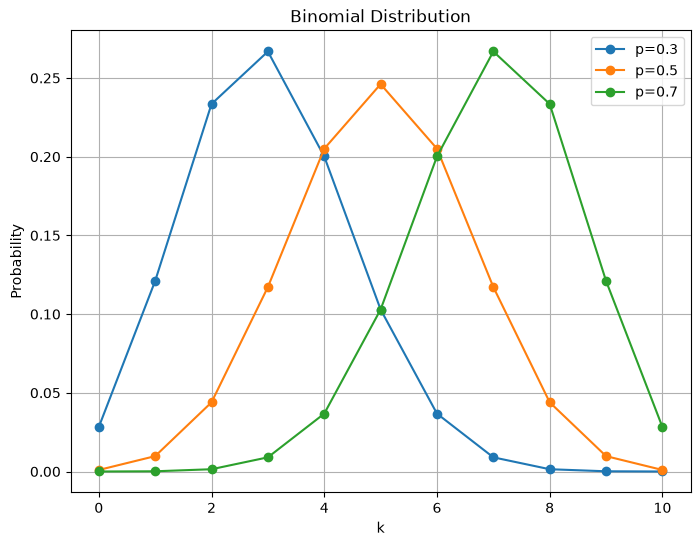

In [14]:
from scipy.stats import binom

# Binomial distribution parameters
n = 10
p_values = [0.3, 0.5, 0.7]

# Values of k (successes)
k = np.arange(0, n + 1)

# Create the figure
plt.figure(figsize=(8, 6))

# Plot the binomial distribution for each probability value
for p in p_values:
    # Calculate probability for each value of k
    probability = binom.pmf(k, n, p)

    # Plot the binomial distribution
    plt.plot(k, probability, 'o-', label=f'p={p}')

# Set axis labels, title, and legend
plt.xlabel('k')
plt.ylabel('Probability')
plt.title('Binomial Distribution')
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

#### **Geometric Distribution**
Number of trials $k$ until the first success occurs.

$P(X = k) = (1-p)^{k-1}p, \quad k = 1, 2, ...$

$E(X) = \frac{1}{p} \quad Var(X) = \frac{1-p}{p^2}$

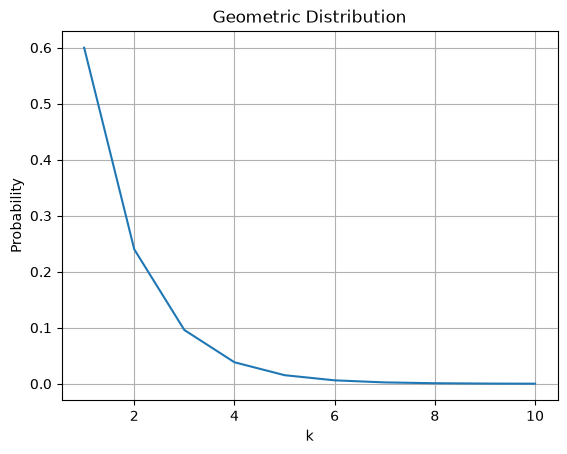

In [15]:
from scipy.stats import geom

# Geometric distribution parameter
p = 0.6

# Values of k (number of trials until first success)
k = np.arange(1, 11)

# Calculate probability for each value of k
probability = geom.pmf(k, p)

# Create geometric distribution chart
plt.plot(k, probability)
plt.xlabel('k')
plt.ylabel('Probability')
plt.title('Geometric Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Negative Binomial Distribution** (Pascal)
Generalizes the geometric distribution: counts the number of failures $r$ before obtaining the $k$-th success (this is the parameterization used by SciPy's `nbinom`).

$P(X = r) = \binom{r+k-1}{r}p^k(1-p)^{r}, \quad r = 0, 1, 2, ...$

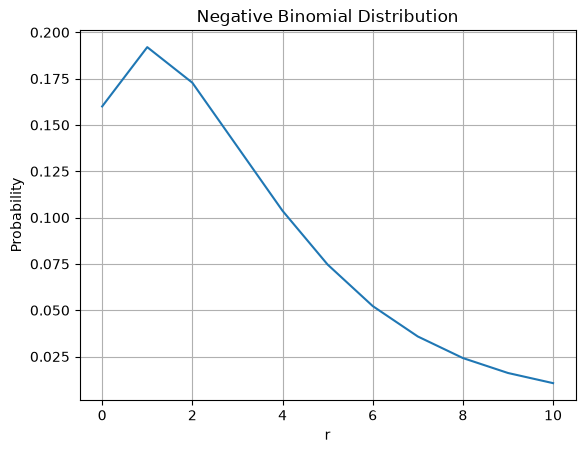

In [16]:
from scipy.stats import nbinom

# Negative binomial distribution parameters
k = 2
p = 0.4

# Values of r (number of failures before obtaining k successes)
r = np.arange(0, 11)

# Calculate probability for each value of r
probability = nbinom.pmf(r, k, p)

# Create negative binomial distribution chart
plt.plot(r, probability)
plt.xlabel('r')
plt.ylabel('Probability')
plt.title('Negative Binomial Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Hypergeometric Distribution**
Number of elements of interest $k$ in a sample of size $n$ drawn **without replacement** from a population of size $N$ containing $K$ elements of interest.

$P(X = k) = \frac{\binom{K}{k}\binom{N-K}{n-k}}{\binom{N}{n}}$

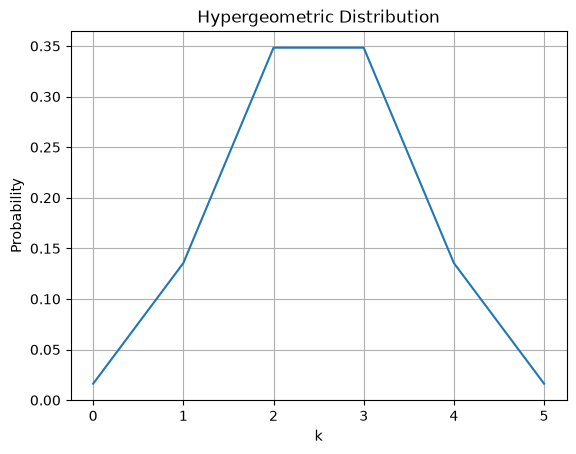

In [17]:
from scipy.stats import hypergeom

# Hypergeometric distribution parameters
N = 20  # Population size
K = 10  # Number of elements of interest in the population
n = 5   # Sample size

# Values of k (number of elements of interest in the sample)
k = np.arange(0, n + 1)

# Calculate probability for each value of k
probability = hypergeom.pmf(k, N, K, n)

# Create hypergeometric distribution chart
plt.plot(k, probability)
plt.xlabel('k')
plt.ylabel('Probability')
plt.title('Hypergeometric Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Poisson Distribution**
Number of occurrences $k$ of an event within a fixed interval of time or space, when occurrences are independent and happen at an average rate $\lambda$.

$P(X = k) = \frac{e^{-\lambda}\lambda^k}{k!}, \quad k = 0, 1, 2, ...$

$E(X) = Var(X) = \lambda$

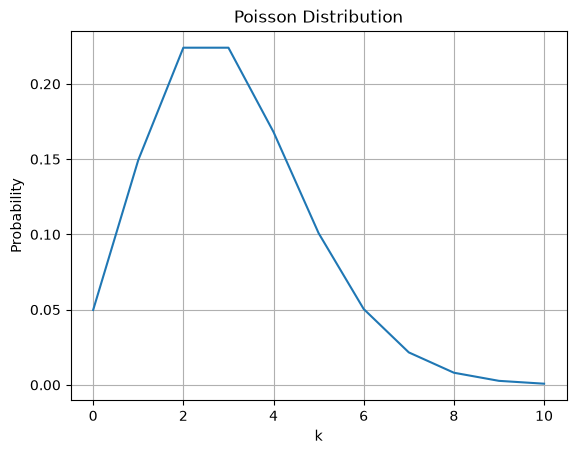

In [18]:
from scipy.stats import poisson

# Lambda parameter of the Poisson distribution
lmbda = 3

# Values of k (number of occurrences)
k = np.arange(0, 11)

# Calculate probability for each value of k
probability = poisson.pmf(k, lmbda)

# Create Poisson distribution chart
plt.plot(k, probability)
plt.xlabel('k')
plt.ylabel('Probability')
plt.title('Poisson Distribution')
plt.grid(True)

# Display the chart
plt.show()

### **Probability Distributions for Continuous Random Variables**

#### **Uniform Distribution**
All values within the interval $[a, b]$ have the same density.

$f(x) = \frac{1}{b - a}, \quad a \leq x \leq b$

$E(X) = \frac{a+b}{2} \quad Var(X) = \frac{(b-a)^2}{12}$

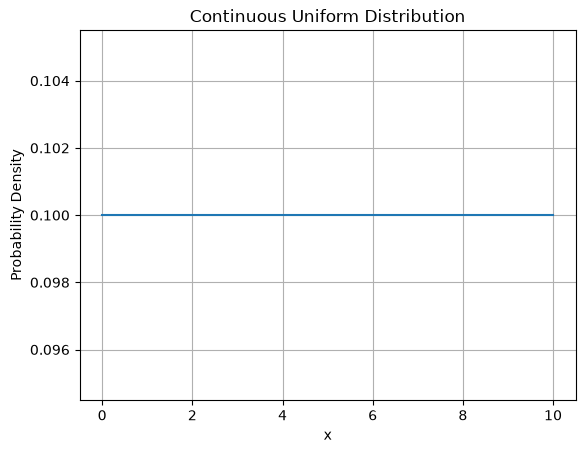

In [19]:
from scipy.stats import uniform

# Continuous uniform distribution parameters
a = 0   # Lower bound
b = 10  # Upper bound

# Values of x
x = np.linspace(a, b, 100)

# Calculate probability density for each value of x
pdf = uniform.pdf(x, a, b - a)

# Create continuous uniform distribution chart
plt.plot(x, pdf)
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Continuous Uniform Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Normal Distribution**
The most important distribution in statistics: symmetric around the mean $\mu$ and bell-shaped.

$f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$

With $\mu = 0$ and $\sigma = 1$ we obtain the standard normal distribution, and any normal distribution can be standardized via $Z = \frac{X - \mu}{\sigma}$.

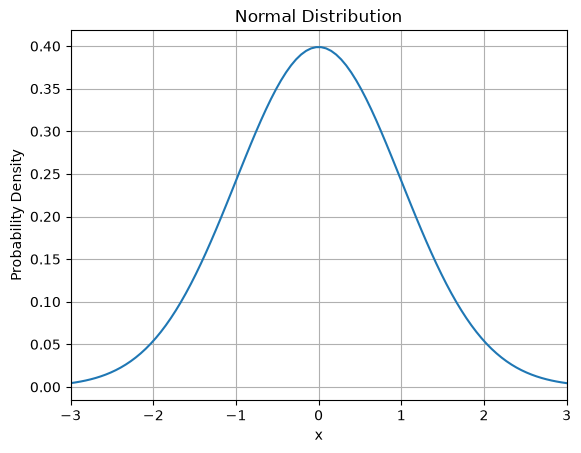

In [20]:
from scipy.stats import norm

# Normal distribution parameters
mu = 0     # Mean
sigma = 1  # Standard deviation

# Values of x
x = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)

# Calculate probability density for each value of x
pdf = norm.pdf(x, mu, sigma)

# Create normal distribution chart
plt.plot(x, pdf)
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Normal Distribution')
plt.grid(True)

# Set x-axis limits
plt.xlim(mu - 3*sigma, mu + 3*sigma)

# Display the chart
plt.show()

#### **Exponential Distribution**
Time between occurrences of a Poisson process with rate $\lambda$.

$f(x) = \lambda e^{-\lambda x}, \quad x \geq 0$

$E(X) = \frac{1}{\lambda} \quad Var(X) = \frac{1}{\lambda^2}$

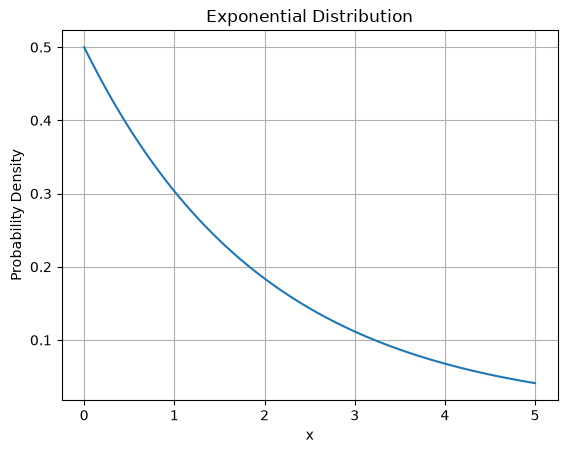

In [21]:
from scipy.stats import expon

# Lambda parameter of the exponential distribution
lmbda = 0.5

# Values of x
x = np.linspace(0, 5, 100)

# Calculate probability density for each value of x
pdf = expon.pdf(x, scale=1/lmbda)

# Create exponential distribution chart
plt.plot(x, pdf)
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Exponential Distribution')
plt.grid(True)

# Display the chart
plt.show()

#### **Gamma Distribution**
Generalizes the exponential distribution: with shape parameter $\alpha$ and rate $\lambda$, it represents the time until the occurrence of the $\alpha$-th event in a Poisson process.

$f(x) = \frac{\lambda^\alpha x^{\alpha-1}e^{-\lambda x}}{\Gamma(\alpha)}, \quad x \geq 0$

`NOTE:` *When $\alpha = 1$, the gamma distribution reduces to the exponential distribution.*

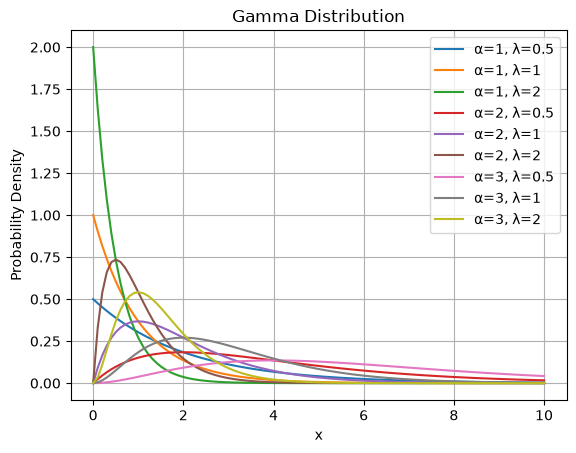

In [22]:
from scipy.stats import gamma

# Gamma distribution parameters
alpha_values = [1, 2, 3]    # Alpha values
lambda_values = [0.5, 1, 2] # Lambda values

# Values of x
x = np.linspace(0, 10, 100)

# Plot the gamma distribution for each combination of alpha and lambda
for alpha in alpha_values:
    for lmbda in lambda_values:
        # Calculate probability density for each value of x
        pdf = gamma.pdf(x, alpha, scale=1/lmbda)

        # Plot the gamma distribution
        label = f'α={alpha}, λ={lmbda}'
        plt.plot(x, pdf, label=label)

# Set axis labels, chart title, and legend
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Gamma Distribution')
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

#### **Chi-Square Distribution**
Sum of the squares of $\nu$ independent standard normal variables: $\chi^2_\nu = Z_1^2 + ... + Z_\nu^2$. It is a special case of the gamma distribution with $\alpha = \frac{\nu}{2}$ and $\lambda = \frac{1}{2}$, and is used in tests of independence and goodness-of-fit.

$E(X) = \nu \quad Var(X) = 2\nu$

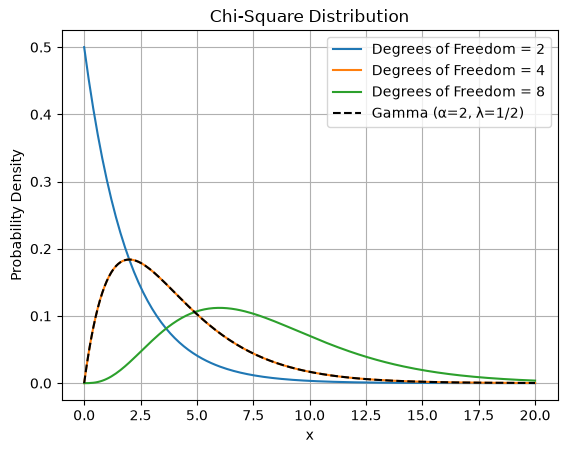

In [23]:
from scipy.stats import chi2, gamma

# Degrees of freedom of the chi-square distribution
df_values = [2, 4, 8]

# Values of x
x = np.linspace(0, 20, 200)

# Plot the chi-square distribution for each degree of freedom
for df in df_values:
    plt.plot(x, chi2.pdf(x, df), label=f'Degrees of Freedom = {df}')

# Check: chi-square with 4 degrees of freedom is a gamma with alpha = 2 and lambda = 1/2
plt.plot(x, gamma.pdf(x, 4/2, scale=2), 'k--', label='Gamma (α=2, λ=1/2)')

# Set axis labels, chart title, and legend
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title('Chi-Square Distribution')
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

#### **Student's t-Distribution**
Symmetric and bell-shaped like the normal distribution, but with heavier tails. It is used when the population standard deviation is unknown and estimated from the sample. As the degrees of freedom $\nu$ increase, it approaches the standard normal distribution.

$T = \frac{Z}{\sqrt{\chi^2_\nu / \nu}}$

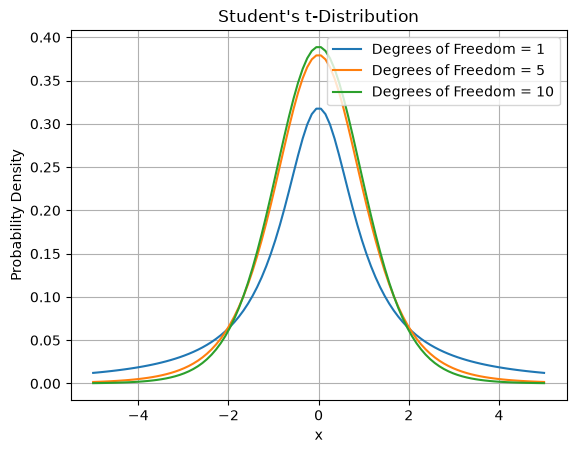

In [24]:
from scipy.stats import t

# Degrees of freedom of the t-distribution
df_values = [1, 5, 10]

# Values of x
x = np.linspace(-5, 5, 100)

# Plot the t-distribution for each degree of freedom
for df in df_values:
    # Calculate probability density for each value of x
    pdf = t.pdf(x, df)

    # Plot the t-distribution
    label = f'Degrees of Freedom = {df}'
    plt.plot(x, pdf, label=label)

# Set axis labels, chart title, and legend
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title("Student's t-Distribution")
plt.legend()
plt.grid(True)

# Display the chart
plt.show()

#### **Snedecor's F-Distribution**
Ratio of two independent chi-square variables divided by their respective degrees of freedom. It is used to compare variances and in Analysis of Variance (ANOVA).

$F = \frac{\chi^2_{\nu_1}/\nu_1}{\chi^2_{\nu_2}/\nu_2}$

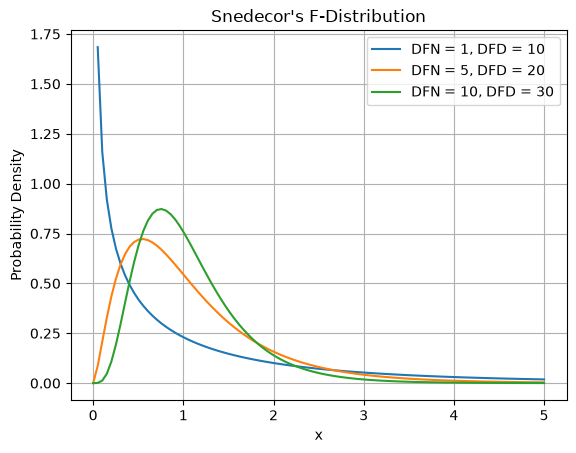

In [25]:
from scipy.stats import f

# Degrees of freedom of Snedecor's F-distribution
dfn_values = [1, 5, 10]
dfd_values = [10, 20, 30]

# Values of x
x = np.linspace(0, 5, 100)

# Plot Snedecor's F-distribution for each combination of degrees of freedom
for dfn, dfd in zip(dfn_values, dfd_values):
    # Calculate probability density for each value of x
    pdf = f.pdf(x, dfn, dfd)

    # Plot Snedecor's F-distribution
    label = f'DFN = {dfn}, DFD = {dfd}'
    plt.plot(x, pdf, label=label)

# Set axis labels, chart title, and legend
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.title("Snedecor's F-Distribution")
plt.legend()
plt.grid(True)

# Display the chart
plt.show()